In [ ]:

# Restore the dataset after the Colab runtime reset

!pip -q install datasets

from datasets import load_dataset

dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

df = dataset.to_pandas()

print("Dataset restored successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])



Dataset restored successfully.
Rows: 560486
Columns: 972


In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

print("Total visits:", dataset.num_rows)
print("Total variables:", dataset.num_columns)


README.md:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

full_data.parquet: reconstructing file:   0%|          |  0.00B / 64.8MB            

full_data.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/560486 [00:00<?, ? examples/s]

Total visits: 560486
Total variables: 972


In [ ]:

columns = dataset.column_names

print("TOTAL VARIABLES:", len(columns))

terms = [
    "triage", "esi", "vital", "complaint",
    "history", "prior", "previous", "diagnos",
    "medication", "admit", "disposition",
    "hospital", "site", "facility", "patient_id"
]

for term in terms:
    matches = [
        col for col in columns
        if term in col.lower()
    ]
    print(f"\n{term.upper()} ({len(matches)} matches)")
    print(matches[:20])


TOTAL VARIABLES: 972

TRIAGE (7 matches)
['triage_vital_hr', 'triage_vital_sbp', 'triage_vital_dbp', 'triage_vital_rr', 'triage_vital_o2', 'triage_vital_o2_device', 'triage_vital_temp']

ESI (9 matches)
['esi', 'magnesium_last', 'magnesium_min', 'magnesium_max', 'magnesium_median', 'meds_analgesicandantihistaminecombination', 'meds_analgesics', 'meds_anti-obesitydrugs', 'cc_emesis']

VITAL (7 matches)
['triage_vital_hr', 'triage_vital_sbp', 'triage_vital_dbp', 'triage_vital_rr', 'triage_vital_o2', 'triage_vital_o2_device', 'triage_vital_temp']

COMPLAINT (0 matches)
[]

HISTORY (1 matches)
['screeningandhistoryofmentalhealthan']

PRIOR (1 matches)
['cc_seizure-priorhxof']

PREVIOUS (1 matches)
['previousdispo']

DIAGNOS (2 matches)
['disordersusuallydiagnosedininfancych', 'meds_diagnostic']

MEDICATION (2 matches)
['cc_medicationproblem', 'cc_medicationrefill']

ADMIT (0 matches)
[]

DISPOSITION (1 matches)
['disposition']

HOSPITAL (0 matches)
[]

SITE (0 matches)
[]

FACILITY (0 matc

In [ ]:

import pandas as pd

df = dataset.to_pandas()

print("Disposition categories:")
print(df["disposition"].value_counts(dropna=False).head(20))

print("\nESI categories:")
print(df["esi"].value_counts(dropna=False).sort_index())

print("\nPrevious disposition categories:")
print(df["previousdispo"].value_counts(dropna=False).head(20))

print("\nFirst 10 rows of key variables:")
print(
    df[["disposition", "esi", "previousdispo",
        "triage_vital_hr", "triage_vital_sbp",
        "triage_vital_dbp", "triage_vital_rr",
        "triage_vital_o2", "triage_vital_temp"]].head(10)
)


Disposition categories:
disposition
Discharge    393848
Admit        166638
Name: count, dtype: int64

ESI categories:
esi
1         5271
2       163534
3       236229
4       125003
5        27992
None      2457
Name: count, dtype: int64

Previous disposition categories:
previousdispo
Discharge                       262237
No previous dispo               164014
Admit                           117878
Transfer to Another Facility      6174
LWBS after Triage                 4771
AMA                               2529
Eloped                            1552
LWBS before Triage                 797
Observation                        326
Send to L&D                        208
Name: count, dtype: int64

First 10 rows of key variables:
  disposition esi      previousdispo  triage_vital_hr  triage_vital_sbp  \
0   Discharge   4  No previous dispo             63.0             146.0   
1   Discharge   4  No previous dispo             83.0             125.0   
2   Discharge   2          Discharge   

In [ ]:

# Print all variables that may represent history,
# prior healthcare use, or chief complaints.

for prefix in ["prev", "cc_", "meds_", "age", "triage_"]:
    matches = [c for c in df.columns if c.lower().startswith(prefix)]
    print(f"\n{prefix} — {len(matches)} variables")
    print(matches[:40])



prev — 2 variables
['previousdispo', 'prevcsectn']

cc_ — 200 variables
['cc_abdominalcramping', 'cc_abdominaldistention', 'cc_abdominalpain', 'cc_abdominalpainpregnant', 'cc_abnormallab', 'cc_abscess', 'cc_addictionproblem', 'cc_agitation', 'cc_alcoholintoxication', 'cc_alcoholproblem', 'cc_allergicreaction', 'cc_alteredmentalstatus', 'cc_animalbite', 'cc_ankleinjury', 'cc_anklepain', 'cc_anxiety', 'cc_arminjury', 'cc_armpain', 'cc_armswelling', 'cc_assaultvictim', 'cc_asthma', 'cc_backpain', 'cc_bleeding/bruising', 'cc_blurredvision', 'cc_bodyfluidexposure', 'cc_breastpain', 'cc_breathingdifficulty', 'cc_breathingproblem', 'cc_burn', 'cc_cardiacarrest', 'cc_cellulitis', 'cc_chestpain', 'cc_chesttightness', 'cc_chills', 'cc_coldlikesymptoms', 'cc_confusion', 'cc_conjunctivitis', 'cc_constipation', 'cc_cough', 'cc_cyst']

meds_ — 48 variables
['meds_analgesicandantihistaminecombination', 'meds_analgesics', 'meds_anesthetics', 'meds_anti-obesitydrugs', 'meds_antiallergy', 'meds_antiart

In [ ]:

# 1. Check the outcome distribution
print("Outcome counts:")
print(df["disposition"].value_counts())

print("\nOutcome proportions:")
print(df["disposition"].value_counts(normalize=True).round(3))

# 2. Inspect variable types
print("\nData types:")
print(df.dtypes.value_counts())

# 3. Identify variables with the most missing values
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print("\nTop 25 variables by percentage missing:")
print(missing.head(25).round(1))

# 4. Inspect potentially relevant historical variables
history_terms = [
    "previous", "prev", "history", "hx_",
    "historical", "outpatient", "usage",
    "prior", "age"
]

history_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in history_terms)
]

print("\nPotential history-related variables:")
print(history_columns)


Outcome counts:
disposition
Discharge    393848
Admit        166638
Name: count, dtype: int64

Outcome proportions:
disposition
Discharge    0.703
Admit        0.297
Name: proportion, dtype: float64

Data types:
float64    954
object      16
int32        2
Name: count, dtype: int64

Top 25 variables by percentage missing:
phencyclidine(pcp)screen,urine,noconf._last      100.0
phencyclidine(pcp)screen,urine,noconf._median    100.0
phencyclidine(pcp)screen,urine,noconf._min       100.0
phencyclidine(pcp)screen,urine,noconf._max       100.0
benzodiazepinesscreen,urine,noconf._last         100.0
epithelialcells_last                             100.0
benzodiazepinesscreen,urine,noconf._median       100.0
benzodiazepinesscreen,urine,noconf._min          100.0
benzodiazepinesscreen,urine,noconf._max          100.0
epithelialcells_median                           100.0
epithelialcells_max                              100.0
epithelialcells_min                              100.0
acetonebld_last 

In [ ]:

# Show all non-numeric columns and their distinct values.
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(8))

# Look for columns that could identify patients or encounters.
print("\nPossible identifiers:")
for col in df.columns:
    name = col.lower()
    if any(term in name for term in [
        "patient", "encounter", "visit", "subject",
        "account", "mrn", "hospital", "site", "facility",
        "date", "time", "arrival"
    ]):
        print(col)



dep_name
Unique values: 3
dep_name
A    322283
B    166497
C     71706
Name: count, dtype: int64

esi
Unique values: 6
esi
3       236229
2       163534
4       125003
5        27992
1         5271
None      2457
Name: count, dtype: int64

gender
Unique values: 2
gender
Female    309653
Male      250833
Name: count, dtype: int64

ethnicity
Unique values: 4
ethnicity
Non-Hispanic          462723
Hispanic or Latino     93584
Unknown                 2812
Patient Refused         1367
Name: count, dtype: int64

race
Unique values: 9
race
White or Caucasian                           299632
Black or African American                    157884
Other                                         89359
Asian                                          5790
Patient Refused                                5203
Unknown                                        1702
American Indian or Alaska Native                515
Native Hawaiian or Other Pacific Islander       375
Name: count, dtype: int64

lang
Unique value

In [ ]:

# Search for variables related to previous encounters,
# patient history, and healthcare utilisation.

terms = [
    "previous", "prev", "history", "prior",
    "encounter", "visit", "admission", "admit",
    "discharge", "utilization", "utilisation",
    "count", "numberof"
]

for term in terms:
    matches = [c for c in df.columns if term in c.lower()]
    if matches:
        print(f"\n{term.upper()}:")
        print(matches)



PREVIOUS:
['previousdispo']

PREV:
['previousdispo', 'prevcsectn']

HISTORY:
['screeningandhistoryofmentalhealthan']

PRIOR:
['cc_seizure-priorhxof']

VISIT:
['n_edvisits']

ADMISSION:
['n_admissions']

DISCHARGE:
['cc_vaginaldischarge']

COUNT:
['absolutelymphocytecount_last', 'anc(absneutrophilcount)_last', 'absolutelymphocytecount_min', 'anc(absneutrophilcount)_min', 'absolutelymphocytecount_max', 'anc(absneutrophilcount)_max', 'absolutelymphocytecount_median', 'anc(absneutrophilcount)_median', 'bloodua_count', 'glucoseua_count', 'ketonesua_count', 'leukocytesua_count', 'nitriteua_count', 'pregtestur_count', 'proteinua_count', 'bloodculture,routine_count', 'urineculture,routine_count', 'cxr_count', 'echo_count', 'ekg_count', 'headct_count', 'mri_count', 'otherct_count', 'otherimg_count', 'otherus_count', 'otherxr_count']


In [ ]:

# Inspect healthcare-utilisation variables
cols_to_check = ["n_edvisits", "n_admissions", "previousdispo", "prevcsectn"]

for col in cols_to_check:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print("Data type:", df[col].dtype)
        print("Missing values:", df[col].isna().sum())
        print("Unique values:", df[col].nunique(dropna=False))

        if df[col].nunique() <= 15:
            print(df[col].value_counts(dropna=False).head(15))
        else:
            print(df[col].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]))



--- n_edvisits ---
Data type: int32
Missing values: 0
Unique values: 373
count    560486.000000
mean          3.659895
std          10.658003
min           0.000000
25%           0.000000
50%           1.000000
75%           3.000000
95%          14.000000
99%          45.000000
max         376.000000
Name: n_edvisits, dtype: float64

--- n_admissions ---
Data type: int32
Missing values: 0
Unique values: 51
count    560486.000000
mean          0.928821
std           2.447036
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
95%           5.000000
99%          11.000000
max          50.000000
Name: n_admissions, dtype: float64

--- previousdispo ---
Data type: object
Missing values: 0
Unique values: 10
previousdispo
Discharge                       262237
No previous dispo               164014
Admit                           117878
Transfer to Another Facility      6174
LWBS after Triage                 4771
AMA                               252

In [ ]:

# Compare utilisation variables across the two outcomes
for col in ["n_edvisits", "n_admissions"]:
    if col in df.columns:
        print(f"\n--- {col} by disposition ---")
        print(
            df.groupby("disposition", dropna=False)[col]
              .agg(["count", "mean", "median", "std"])
        )

print("\n--- Previous disposition by current disposition ---")
print(pd.crosstab(
    df["previousdispo"],
    df["disposition"],
    normalize="index"
).round(3))



--- n_edvisits by disposition ---
              count      mean  median        std
disposition                                     
Admit        166638  3.337576     1.0   6.957798
Discharge    393848  3.796269     1.0  11.878946

--- n_admissions by disposition ---
              count      mean  median       std
disposition                                    
Admit        166638  1.625032     0.0  3.142134
Discharge    393848  0.634252     0.0  2.013055

--- Previous disposition by current disposition ---
disposition                   Admit  Discharge
previousdispo                                 
AMA                           0.351      0.649
Admit                         0.569      0.431
Discharge                     0.199      0.801
Eloped                        0.203      0.797
LWBS after Triage             0.159      0.841
LWBS before Triage            0.154      0.846
No previous dispo             0.264      0.736
Observation                   0.368      0.632
Send to L&D      

In [ ]:

# Candidate information available at or near triage
current_visit_cols = [
    "age", "gender", "arrivalmode", "arrivalmonth",
    "arrivalday", "arrivalhour_bin", "esi",
    "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = [
    "n_edvisits", "n_admissions", "previousdispo"
]

candidate_cols = [
    c for c in current_visit_cols + history_cols
    if c in df.columns
]

audit = pd.DataFrame({
    "data_type": df[candidate_cols].dtypes.astype(str),
    "missing_count": df[candidate_cols].isna().sum(),
    "missing_percent": (df[candidate_cols].isna().mean() * 100).round(2),
    "unique_values": df[candidate_cols].nunique(dropna=False)
})

print(audit.to_string())
print("\nChief complaint indicators:", sum(c.startswith("cc_") for c in df.columns))
print("Department labels:", df["dep_name"].value_counts(dropna=False).to_dict())
print("\nAge summary:")
print(df["age"].describe())


                  data_type  missing_count  missing_percent  unique_values
age                 float64             11             0.00             92
gender               object              0             0.00              2
arrivalmode          object          21884             3.90              8
arrivalmonth         object              0             0.00             12
arrivalday           object              0             0.00              7
arrivalhour_bin      object              0             0.00              6
esi                  object           2457             0.44              6
triage_vital_hr     float64         166052            29.63            422
triage_vital_sbp    float64         167904            29.96            528
triage_vital_dbp    float64         168063            29.99            383
triage_vital_rr     float64         170487            30.42            105
triage_vital_o2     float64         271317            48.41             82
triage_vital_temp   float

In [ ]:

# Candidate information available at or near triage
current_visit_cols = [
    "age", "gender", "arrivalmode", "arrivalmonth",
    "arrivalday", "arrivalhour_bin", "esi",
    "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = [
    "n_edvisits", "n_admissions", "previousdispo"
]

candidate_cols = [
    c for c in current_visit_cols + history_cols
    if c in df.columns
]

audit = pd.DataFrame({
    "data_type": df[candidate_cols].dtypes.astype(str),
    "missing_count": df[candidate_cols].isna().sum(),
    "missing_percent": (df[candidate_cols].isna().mean() * 100).round(2),
    "unique_values": df[candidate_cols].nunique(dropna=False)
})

print(audit.to_string())
print("\nChief complaint indicators:", sum(c.startswith("cc_") for c in df.columns))
print("Department labels:", df["dep_name"].value_counts(dropna=False).to_dict())
print("\nAge summary:")
print(df["age"].describe())


                  data_type  missing_count  missing_percent  unique_values
age                 float64             11             0.00             92
gender               object              0             0.00              2
arrivalmode          object          21884             3.90              8
arrivalmonth         object              0             0.00             12
arrivalday           object              0             0.00              7
arrivalhour_bin      object              0             0.00              6
esi                  object           2457             0.44              6
triage_vital_hr     float64         166052            29.63            422
triage_vital_sbp    float64         167904            29.96            528
triage_vital_dbp    float64         168063            29.99            383
triage_vital_rr     float64         170487            30.42            105
triage_vital_o2     float64         271317            48.41             82
triage_vital_temp   float

In [ ]:

# Inspect how chief-complaint indicators are encoded
cc_cols = [c for c in df.columns if c.startswith("cc_")]

print("Number of chief-complaint variables:", len(cc_cols))

# Inspect values in a sample of complaint columns
print("\nSample complaint variables:")
for col in cc_cols[:12]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(5).to_dict())

# Check whether these variables are predominantly binary
binary_cols = []
nonbinary_cols = []

for col in cc_cols:
    values = set(df[col].dropna().unique())
    if values.issubset({0, 1, 0.0, 1.0}):
        binary_cols.append(col)
    else:
        nonbinary_cols.append(col)

print("\nBinary complaint variables:", len(binary_cols))
print("Non-binary complaint variables:", len(nonbinary_cols))

# Most frequent complaint indicators
if binary_cols:
    complaint_prevalence = (
        df[binary_cols].eq(1).mean()
        .sort_values(ascending=False)
    )
    print("\n15 most frequent complaint indicators:")
    print((complaint_prevalence.head(15) * 100).round(2).astype(str) + "%")

# Missingness in complaint indicators
print("\nComplaint-variable missingness:")
print("Total missing entries:", int(df[cc_cols].isna().sum().sum()))
print("Percentage of all complaint entries missing:",
      round(df[cc_cols].isna().mean().mean() * 100, 3), "%")


Number of chief-complaint variables: 200

Sample complaint variables:

cc_abdominalcramping
{0.0: 557317, nan: 2585, 1.0: 584}

cc_abdominaldistention
{0.0: 557274, nan: 2585, 1.0: 626, 2.0: 1}

cc_abdominalpain
{0.0: 503571, 1.0: 54315, nan: 2585, 2.0: 15}

cc_abdominalpainpregnant
{0.0: 555847, nan: 2585, 1.0: 2051, 2.0: 3}

cc_abnormallab
{0.0: 554175, 1.0: 3723, nan: 2585, 2.0: 3}

cc_abscess
{0.0: 554387, 1.0: 3514, nan: 2585}

cc_addictionproblem
{0.0: 557202, nan: 2585, 1.0: 699}

cc_agitation
{0.0: 557247, nan: 2585, 1.0: 654}

cc_alcoholintoxication
{0.0: 541966, 1.0: 15931, nan: 2585, 2.0: 4}

cc_alcoholproblem
{0.0: 555663, nan: 2585, 1.0: 2237, 2.0: 1}

cc_allergicreaction
{0.0: 554576, 1.0: 3321, nan: 2585, 2.0: 4}

cc_alteredmentalstatus
{0.0: 549349, 1.0: 8547, nan: 2585, 2.0: 5}

Binary complaint variables: 123
Non-binary complaint variables: 77

15 most frequent complaint indicators:
cc_flankpain                1.59%
cc_weakness                  1.3%
cc_kneepain       

In [ ]:

# Investigate non-binary chief-complaint indicators
for col in nonbinary_cols:
    unusual = df.loc[
        df[col].notna() & ~df[col].isin([0, 1]),
        col
    ].value_counts().sort_index()

    if len(unusual) > 0:
        print(f"\n{col}")
        print(unusual.to_dict())

# Summarise all non-binary values across complaint variables
unusual_counts = {}

for col in cc_cols:
    mask = df[col].notna() & ~df[col].isin([0, 1])
    if mask.any():
        for value, count in df.loc[mask, col].value_counts().items():
            key = (col, value)
            unusual_counts[key] = int(count)

print("\nTotal non-binary entries:", sum(unusual_counts.values()))
print("Distinct variable-value combinations:", len(unusual_counts))
print("First 30 unusual entries:")
print(list(unusual_counts.items())[:30])



cc_abdominaldistention
{2.0: 1}

cc_abdominalpain
{2.0: 15}

cc_abdominalpainpregnant
{2.0: 3}

cc_abnormallab
{2.0: 3}

cc_alcoholintoxication
{2.0: 4}

cc_alcoholproblem
{2.0: 1}

cc_allergicreaction
{2.0: 4}

cc_alteredmentalstatus
{2.0: 5}

cc_ankleinjury
{2.0: 1}

cc_anxiety
{2.0: 1}

cc_armpain
{2.0: 1}

cc_assaultvictim
{2.0: 1}

cc_asthma
{2.0: 2}

cc_backpain
{2.0: 5}

cc_bleeding/bruising
{2.0: 1}

cc_bodyfluidexposure
{2.0: 1}

cc_chestpain
{2.0: 10}

cc_chesttightness
{2.0: 1}

cc_coldlikesymptoms
{2.0: 1}

cc_conjunctivitis
{2.0: 1}

cc_cough
{2.0: 2}

cc_cyst
{2.0: 1}

cc_dehydration
{2.0: 1}

cc_depression
{2.0: 2}

cc_detoxevaluation
{2.0: 1}

cc_diarrhea
{2.0: 1}

cc_dizziness
{2.0: 4}

cc_elevatedbloodsugar-nosymptoms
{2.0: 1}

cc_emesis
{2.0: 3}

cc_epistaxis
{2.0: 1}

cc_extremitylaceration
{2.0: 1}

cc_eyepain
{2.0: 1}

cc_eyeproblem
{2.0: 2}

cc_facialswelling
{2.0: 1}

cc_fall
{2.0: 7}

cc_fall>65
{2.0: 1}

cc_fatigue
{2.0: 3}

cc_femaleguproblem
{2.0: 2}

cc_fi

In [ ]:

# Check whether complaint indicators are missing together
cc_cols = [c for c in df.columns if c.startswith("cc_")]

missing_per_row = df[cc_cols].isna().sum(axis=1)

print("Missing complaint indicators per encounter:")
print(missing_per_row.value_counts().sort_index().tail(10))

print("\nEncounters with all complaint indicators missing:",
      (missing_per_row == len(cc_cols)).sum())

print("Encounters with at least one complaint recorded:",
      (missing_per_row < len(cc_cols)).sum())

# Check the number of complaints marked present per encounter
# This is exploratory; we have not changed the original dataframe.
cc_present = df[cc_cols].gt(0).sum(axis=1)

print("\nNumber of complaint indicators marked present per encounter:")
print(cc_present.describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nEncounters with zero complaint indicators marked present:",
      (cc_present == 0).sum())


Missing complaint indicators per encounter:
0      557901
200      2585
Name: count, dtype: int64

Encounters with all complaint indicators missing: 2585
Encounters with at least one complaint recorded: 557901

Number of complaint indicators marked present per encounter:
count    560486.000000
mean          1.131377
std           0.399981
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
95%           2.000000
99%           3.000000
max           7.000000
dtype: float64

Encounters with zero complaint indicators marked present: 2585


In [ ]:

# Inspect dataset metadata and available feature descriptions
print("Dataset features:")
for feature in dataset.features:
    print(feature)

print("\nDataset information:")
print(dataset.info)


Dataset features:
dep_name
esi
age
gender
ethnicity
race
lang
religion
maritalstatus
employstatus
insurance_status
disposition
arrivalmode
arrivalmonth
arrivalday
arrivalhour_bin
previousdispo
2ndarymalig
abdomhernia
abdomnlpain
abortcompl
acqfootdef
acrenlfail
acutecvd
acutemi
acutphanm
adjustmentdisorders
adltrespfl
alcoholrelateddisorders
allergy
amniosdx
analrectal
anemia
aneurysm
anxietydisorders
appendicitis
artembolism
asppneumon
asthma
attentiondeficitconductdisruptivebeha
backproblem
biliarydx
birthasphyx
birthtrauma
bladdercncr
blindness
bnignutneo
bonectcncr
bph
brainnscan
breastcancr
breastdx
brnchlngca
bronchitis
burns
cardiaarrst
cardiacanom
carditis
cataract
cervixcancr
chestpain
chfnonhp
chrkidneydisease
coaghemrdx
coloncancer
comabrndmg
complicdevi
complicproc
conduction
contraceptiv
copd
coronathero
crushinjury
cysticfibro
deliriumdementiaamnesticothercognitiv
developmentaldisorders
diabmelnoc
diabmelwcm
disordersusuallydiagnosedininfancych
diverticulos
dizziness
dmin

In [ ]:

# Cell 14: Examine department-level admission patterns

print("Department categories:")
print(df["dep_name"].value_counts(dropna=False))

print("\nAdmission rate by department:")
department_admission = pd.crosstab(
    df["dep_name"],
    df["disposition"],
    normalize="index"
) * 100

print(department_admission.round(2))

print("\nNumber of visits by department and outcome:")
print(
    pd.crosstab(
        df["dep_name"],
        df["disposition"]
    )
)


Department categories:
dep_name
A    322283
B    166497
C     71706
Name: count, dtype: int64

Admission rate by department:
disposition  Admit  Discharge
dep_name                     
A            31.88      68.12
B            31.65      68.35
C            15.62      84.38

Number of visits by department and outcome:
disposition   Admit  Discharge
dep_name                      
A            102745     219538
B             52695     113802
C             11198      60508


In [ ]:

# Cell 15: Define candidate predictors and audit the modelling dataset

# Outcome: admission versus discharge
print("Outcome categories:")
print(df["disposition"].value_counts(dropna=False))

# Current-visit information available as candidate predictors
triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi",
    "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

# Chief-complaint indicators
cc_cols = [c for c in df.columns if c.startswith("cc_")]

# Historical information
history_cols = [
    "n_edvisits", "n_admissions", "previousdispo"
]

# Check that every requested variable exists
candidate_cols = triage_cols + cc_cols + history_cols
missing_cols = [c for c in candidate_cols if c not in df.columns]

print("\nNumber of complaint variables:", len(cc_cols))
print("Missing expected columns:", missing_cols)

# Inspect missingness in the candidate predictors
audit = pd.DataFrame({
    "dtype": df[candidate_cols].dtypes.astype(str),
    "missing_count": df[candidate_cols].isna().sum(),
    "missing_percent": (
        df[candidate_cols].isna().mean() * 100
    ).round(2),
    "unique_values": df[candidate_cols].nunique(dropna=True)
})

print("\nCandidate predictor audit:")
print(audit.to_string())

# Confirm whether any unexpected outcome categories exist
print("\nOutcome totals:")
print("Total visits:", len(df))
print("Missing outcomes:", df["disposition"].isna().sum())
print("Departments excluded from predictors: dep_name")


Outcome categories:
disposition
Discharge    393848
Admit        166638
Name: count, dtype: int64

Number of complaint variables: 200
Missing expected columns: []

Candidate predictor audit:
                                           dtype  missing_count  missing_percent  unique_values
age                                      float64             11             0.00             91
gender                                    object              0             0.00              2
arrivalmode                               object          21884             3.90              7
arrivalmonth                              object              0             0.00             12
arrivalday                                object              0             0.00              7
arrivalhour_bin                           object              0             0.00              6
esi                                       object           2457             0.44              5
triage_vital_hr                          

In [ ]:

# Cell 16: Inspect complaint coding before transformation

cc_cols = [c for c in df.columns if c.startswith("cc_")]

# Count all observed values across complaint variables
print("Most common values across complaint indicators:")
print(
    df[cc_cols]
    .stack()
    .value_counts(dropna=False)
    .sort_index()
)

# Inspect variables with values outside 0 and 1
nonbinary_summary = []

for col in cc_cols:
    observed = set(df[col].dropna().unique())
    unusual = observed - {0, 1}

    if unusual:
        nonbinary_summary.append({
            "variable": col,
            "observed_values": sorted(observed),
            "unusual_values": sorted(unusual),
            "counts": df[col].value_counts().to_dict()
        })

print("\nNumber of complaint variables with values outside 0/1:",
      len(nonbinary_summary))

for item in nonbinary_summary[:15]:
    print(item)


Most common values across complaint indicators:
0.0    110946079
1.0       633200
2.0          904
3.0           16
4.0            1
Name: count, dtype: int64

Number of complaint variables with values outside 0/1: 77
{'variable': 'cc_abdominaldistention', 'observed_values': [np.float64(0.0), np.float64(1.0), np.float64(2.0)], 'unusual_values': [np.float64(2.0)], 'counts': {0.0: 557274, 1.0: 626, 2.0: 1}}
{'variable': 'cc_abdominalpain', 'observed_values': [np.float64(0.0), np.float64(1.0), np.float64(2.0)], 'unusual_values': [np.float64(2.0)], 'counts': {0.0: 503571, 1.0: 54315, 2.0: 15}}
{'variable': 'cc_abdominalpainpregnant', 'observed_values': [np.float64(0.0), np.float64(1.0), np.float64(2.0)], 'unusual_values': [np.float64(2.0)], 'counts': {0.0: 555847, 1.0: 2051, 2.0: 3}}
{'variable': 'cc_abnormallab', 'observed_values': [np.float64(0.0), np.float64(1.0), np.float64(2.0)], 'unusual_values': [np.float64(2.0)], 'counts': {0.0: 554175, 1.0: 3723, 2.0: 3}}
{'variable': 'cc_alcoholi

In [ ]:

# Cell 17: Prepare features and create a train/test split

import pandas as pd
from sklearn.model_selection import train_test_split

# Identify the 200 chief-complaint variables
cc_cols = [c for c in df.columns if c.startswith("cc_")]

# Define current-visit and history predictors
triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi",
    "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = [
    "n_edvisits", "n_admissions", "previousdispo"
]

# Create a separate modelling table
feature_cols = triage_cols + cc_cols + history_cols
model_df = df[feature_cols + ["disposition"]].copy()

# Record visits where every complaint indicator is missing
model_df["cc_all_missing"] = model_df[cc_cols].isna().all(axis=1).astype(int)

# Explicit assumption: positive values mean complaint present
# Preserve missingness separately using cc_all_missing
model_df[cc_cols] = model_df[cc_cols].gt(0).astype(int)

# Encode the outcome: admission = 1, discharge = 0
y = model_df["disposition"].map({
    "Admit": 1,
    "Discharge": 0
})

# Candidate features for both models
model_a_cols = triage_cols + cc_cols + ["cc_all_missing"]
model_b_cols = model_a_cols + history_cols

X_a = model_df[model_a_cols].copy()
X_b = model_df[model_b_cols].copy()

# Use the same split for both models
X_a_train, X_a_test, y_train, y_test = train_test_split(
    X_a, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_b_train = X_b.loc[X_a_train.index]
X_b_test = X_b.loc[X_a_test.index]

print("Model A features:", len(model_a_cols))
print("Model B features:", len(model_b_cols))
print("Training visits:", len(X_a_train))
print("Test visits:", len(X_a_test))
print("\nTraining admission rate:", round(y_train.mean() * 100, 2), "%")
print("Test admission rate:", round(y_test.mean() * 100, 2), "%")
print("Complaint records entirely missing:",
      int(model_df["cc_all_missing"].sum()))
print("Missing outcome labels:", int(y.isna().sum()))


Model A features: 214
Model B features: 217
Training visits: 448388
Test visits: 112098

Training admission rate: 29.73 %
Test admission rate: 29.73 %
Complaint records entirely missing: 2585
Missing outcome labels: 0


In [ ]:

# Cell 18A: Load only the columns needed for our analysis

!pip -q install datasets scikit-learn

from datasets import load_dataset
import pandas as pd
import numpy as np
import gc

dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

cc_cols = [c for c in dataset.column_names if c.startswith("cc_")]

triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi", "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = ["n_edvisits", "n_admissions", "previousdispo"]

needed_cols = triage_cols + cc_cols + history_cols + [
    "disposition"
]

# Select before converting to pandas
dataset = dataset.select_columns(needed_cols)
df = dataset.to_pandas()

print("Rows and selected columns:", df.shape)
print("Complaint variables:", len(cc_cols))
print("Memory used by DataFrame (GB):",
      round(df.memory_usage(deep=True).sum() / 1e9, 2))
print("\nOutcome counts:")
print(df["disposition"].value_counts(dropna=False))

del dataset
gc.collect()


Rows and selected columns: (560486, 217)
Complaint variables: 200
Memory used by DataFrame (GB): 1.18

Outcome counts:
disposition
Discharge    393848
Admit        166638
Name: count, dtype: int64


95

In [ ]:

# Cell 18B: Create a stratified sample with less memory overhead

import gc

# Allocate the sample proportionally to the outcome counts
n_total = 150_000
outcome_counts = df["disposition"].value_counts()

n_admit = round(
    n_total * outcome_counts["Admit"] / len(df)
)
n_discharge = n_total - n_admit

admit_sample = df.loc[
    df["disposition"] == "Admit"
].sample(n=n_admit, random_state=42)

discharge_sample = df.loc[
    df["disposition"] == "Discharge"
].sample(n=n_discharge, random_state=42)

sampled_df = pd.concat(
    [admit_sample, discharge_sample],
    axis=0
).sample(frac=1, random_state=42)

# Release intermediate objects
del admit_sample, discharge_sample
del df
df = sampled_df
del sampled_df
gc.collect()

print("Sample size:", len(df))
print("\nOutcome counts:")
print(df["disposition"].value_counts())

print("\nOutcome proportions (%):")
print(
    (df["disposition"].value_counts(normalize=True) * 100)
    .round(2)
)

print(
    "\nSample DataFrame memory (GB):",
    round(df.memory_usage(deep=True).sum() / 1e9, 2)
)


Sample size: 150000

Outcome counts:
disposition
Discharge    105404
Admit         44596
Name: count, dtype: int64

Outcome proportions (%):
disposition
Discharge    70.27
Admit        29.73
Name: proportion, dtype: float64

Sample DataFrame memory (GB): 0.32


In [ ]:

# Cell 18C: Prepare data and train Model A

import gc
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

cc_cols = [c for c in df.columns if c.startswith("cc_")]

triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi", "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = ["n_edvisits", "n_admissions", "previousdispo"]

# Record whether all complaint indicators were missing
cc_all_missing = df[cc_cols].isna().all(axis=1).astype("int8")

# Convert complaints to binary: positive means present
# Fill missing complaint entries with zero, retaining the all-missing flag
df[cc_cols] = (
    df[cc_cols].fillna(0).gt(0).astype("int8")
)

df["cc_all_missing"] = cc_all_missing

# Outcome: admission = 1, discharge = 0
y = df["disposition"].map({"Admit": 1, "Discharge": 0}).astype("int8")

model_a_cols = triage_cols + cc_cols + ["cc_all_missing"]
categorical_a = [
    "gender", "arrivalmode", "arrivalmonth",
    "arrivalday", "arrivalhour_bin", "esi"
]

# Split row indices only; avoid creating multiple large DataFrames
train_idx, test_idx = train_test_split(
    df.index.to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = df.loc[train_idx, model_a_cols]
X_test = df.loc[test_idx, model_a_cols]
y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

numeric_a = [c for c in model_a_cols if c not in categorical_a]

preprocessor_a = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler())
    ]), numeric_a),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_a)
])

model_a = Pipeline([
    ("prep", preprocessor_a),
    ("logreg", LogisticRegression(
        solver="liblinear",
        max_iter=200,
        random_state=42
    ))
])

print("Training Model A on", len(train_idx), "visits...")
model_a.fit(X_train, y_train)

prob_a = model_a.predict_proba(X_test)[:, 1]

print("\nModel A trained successfully.")
print("Test visits:", len(test_idx))
print("ROC-AUC:", round(roc_auc_score(y_test, prob_a), 4))
print("Average precision:", round(average_precision_score(y_test, prob_a), 4))

# Release temporary objects where possible
del X_train, X_test, preprocessor_a
gc.collect()


/tmp/ipykernel_46199/1210679278.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cc_all_missing"] = cc_all_missing


Training Model A on 120000 visits...

Model A trained successfully.
Test visits: 30000
ROC-AUC: 0.8685
Average precision: 0.7285


40

In [ ]:

# Cell 18D: Train Model B with historical information

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
import gc

history_cols = ["n_edvisits", "n_admissions", "previousdispo"]

categorical_b = [
    "gender", "arrivalmode", "arrivalmonth",
    "arrivalday", "arrivalhour_bin", "esi",
    "previousdispo"
]

# Model B includes Model A features plus historical information.
# Use the same train/test indices as Model A.
model_b_cols = model_a_cols + history_cols

numeric_b = [
    c for c in model_b_cols
    if c not in categorical_b
]

# Reuse Model A's preprocessing structure, adding history columns.
preprocessor_b = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler())
    ]), numeric_b),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_b)
])

model_b = Pipeline([
    ("prep", preprocessor_b),
    ("logreg", LogisticRegression(
        solver="liblinear",
        max_iter=200,
        random_state=42
    ))
])

print("Training Model B on the same training visits...")
model_b.fit(df.loc[train_idx, model_b_cols], y_train)

prob_b = model_b.predict_proba(
    df.loc[test_idx, model_b_cols]
)[:, 1]

print("\nModel B trained successfully.")
print("ROC-AUC:", round(roc_auc_score(y_test, prob_b), 4))
print("Average precision:", round(average_precision_score(y_test, prob_b), 4))

gc.collect()


Training Model B on the same training visits...

Model B trained successfully.
ROC-AUC: 0.8754
Average precision: 0.7399


40

In [ ]:

# Cell 19: Compare models under fixed prioritisation capacity

import numpy as np
import pandas as pd

def capacity_metrics(y_true, probabilities, model_name):
    results = []
    y_array = np.asarray(y_true)
    p_array = np.asarray(probabilities)

    total_admissions = int(y_array.sum())
    n = len(y_array)

    for capacity in [0.10, 0.20, 0.30]:
        # Select the highest-risk visits
        k = int(np.ceil(capacity * n))
        selected_idx = np.argsort(p_array)[-k:]

        selected_admissions = int(y_array[selected_idx].sum())
        missed_admissions = total_admissions - selected_admissions

        results.append({
            "Model": model_name,
            "Capacity": f"Top {int(capacity * 100)}%",
            "Visits prioritised": k,
            "Admissions captured": selected_admissions,
            "Admissions captured (%)": round(
                100 * selected_admissions / total_admissions, 2
            ),
            "Precision (%)": round(
                100 * selected_admissions / k, 2
            ),
            "Admissions missed": missed_admissions
        })

    return results

results = (
    capacity_metrics(y_test, prob_a, "Model A")
    + capacity_metrics(y_test, prob_b, "Model B")
)

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


  Model Capacity  Visits prioritised  Admissions captured  Admissions captured (%)  Precision (%)  Admissions missed
Model A  Top 10%                3000                 2523                    28.29          84.10               6396
Model A  Top 20%                6000                 4484                    50.27          74.73               4435
Model A  Top 30%                9000                 5979                    67.04          66.43               2940
Model B  Top 10%                3000                 2539                    28.47          84.63               6380
Model B  Top 20%                6000                 4568                    51.22          76.13               4351
Model B  Top 30%                9000                 6093                    68.31          67.70               2826


In [ ]:
required = ["y_test", "prob_a", "prob_b"]

for name in required:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

y_test: available
prob_a: available
prob_b: available


In [ ]:

import numpy as np
import pandas as pd

# Convert the existing test results into NumPy arrays
y_array = np.asarray(y_test, dtype=np.int8)
prob_a_array = np.asarray(prob_a)
prob_b_array = np.asarray(prob_b)

# Check that all arrays refer to the same test visits
assert len(y_array) == len(prob_a_array) == len(prob_b_array)

rng = np.random.default_rng(42)
n = len(y_array)
capacities = [0.10, 0.20, 0.30]
n_bootstrap = 300

bootstrap_differences = {c: [] for c in capacities}

for b in range(n_bootstrap):
    # Resample test visits, keeping both models paired
    idx = rng.integers(0, n, size=n)

    y_boot = y_array[idx]
    a_boot = prob_a_array[idx]
    b_boot = prob_b_array[idx]

    total_admissions = y_boot.sum()

    if total_admissions == 0:
        continue

    for capacity in capacities:
        k = int(np.ceil(capacity * n))

        # Select the highest predicted risks for each model
        top_a = np.argpartition(a_boot, -k)[-k:]
        top_b = np.argpartition(b_boot, -k)[-k:]

        capture_a = y_boot[top_a].sum() / total_admissions
        capture_b = y_boot[top_b].sum() / total_admissions

        # Positive values mean Model B captures more admissions
        bootstrap_differences[capacity].append(
            100 * (capture_b - capture_a)
        )

# Summarise the bootstrap distribution
summary = []

for capacity in capacities:
    differences = np.asarray(bootstrap_differences[capacity])

    summary.append({
        "Capacity": f"Top {int(capacity * 100)}%",
        "Mean improvement (percentage points)": round(
            differences.mean(), 2
        ),
        "95% CI lower": round(
            np.percentile(differences, 2.5), 2
        ),
        "95% CI upper": round(
            np.percentile(differences, 97.5), 2
        ),
        "Bootstrap repetitions": len(differences)
    })

bootstrap_results = pd.DataFrame(summary)
print(bootstrap_results.to_string(index=False))


Capacity  Mean improvement (percentage points)  95% CI lower  95% CI upper  Bootstrap repetitions
 Top 10%                                  0.17         -0.13          0.44                    300
 Top 20%                                  0.96          0.53          1.36                    300
 Top 30%                                  1.29          0.89          1.69                    300


In [ ]:

from datasets import load_dataset

source_dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

all_columns = source_dataset.column_names

possible_ids = [
    col for col in all_columns
    if any(term in col.lower() for term in [
        "patient_id", "subject_id", "person_id",
        "patientid", "subjectid", "encounter_id",
        "visit_id", "mrn"
    ])
]

print("Total original columns:", len(all_columns))
print("Possible identifier columns:", possible_ids)

del source_dataset


Total original columns: 972
Possible identifier columns: []


In [ ]:

from datasets import load_dataset_builder

builder = load_dataset_builder(
    "kondratevakate/hospital-triage-and-patient-history-data"
)

print("Dataset description:")
print(builder.info.description)

print("\nDataset citation:")
print(builder.info.citation)

print("\nDataset features related to history or identifiers:")
for name in builder.info.features:
    if any(term in name.lower() for term in [
        "patient", "subject", "encounter", "visit",
        "history", "edvisit", "admission", "dispo"
    ]):
        print(name, ":", builder.info.features[name])


Dataset description:


Dataset citation:


Dataset features related to history or identifiers:
disposition : Value('string')
previousdispo : Value('string')
screeningandhistoryofmentalhealthan : Value('float64')
n_edvisits : Value('int32')
n_admissions : Value('int32')


In [ ]:

import numpy as np
import pandas as pd

# Recover the ESI values in exactly the same order as the test set
esi_test = pd.to_numeric(
    df.loc[y_test.index, "esi"], errors="coerce"
).to_numpy()

y_array = np.asarray(y_test, dtype=int)
prob_a_array = np.asarray(prob_a)
prob_b_array = np.asarray(prob_b)

assert len(esi_test) == len(y_array) == len(prob_a_array) == len(prob_b_array)

# Fixed random numbers make ties reproducible
rng = np.random.default_rng(42)
tie_breaker = rng.random(len(y_array))

# Lower ESI means higher acuity.
# Missing ESI values are placed after all recorded ESI levels.
esi_rank = np.where(np.isnan(esi_test), 999, esi_test)

# Sort: lowest ESI first, then random tie-breaker
esi_order = np.lexsort((tie_breaker, esi_rank))

def evaluate_ranking(y_true, ranking, method_name):
    n = len(y_true)
    total_admissions = int(np.sum(y_true))
    rows = []

    for capacity in [0.10, 0.20, 0.30]:
        k = int(np.ceil(capacity * n))
        selected = ranking[:k]
        captured = int(np.sum(y_true[selected]))

        rows.append({
            "Method": method_name,
            "Capacity": f"Top {int(capacity * 100)}%",
            "Visits prioritised": k,
            "Admissions captured": captured,
            "Admissions captured (%)": round(
                100 * captured / total_admissions, 2
            ),
            "Precision (%)": round(100 * captured / k, 2),
            "Admissions missed": total_admissions - captured
        })

    return rows

# Convert model probabilities into descending risk rankings
order_a = np.argsort(-prob_a_array, kind="stable")
order_b = np.argsort(-prob_b_array, kind="stable")

benchmark_results = (
    evaluate_ranking(y_array, esi_order, "ESI only")
    + evaluate_ranking(y_array, order_a, "Model A")
    + evaluate_ranking(y_array, order_b, "Model B")
)

benchmark_df = pd.DataFrame(benchmark_results)
print(benchmark_df.to_string(index=False))


  Method Capacity  Visits prioritised  Admissions captured  Admissions captured (%)  Precision (%)  Admissions missed
ESI only  Top 10%                3000                 1766                    19.80          58.87               7153
ESI only  Top 20%                6000                 3442                    38.59          57.37               5477
ESI only  Top 30%                9000                 5097                    57.15          56.63               3822
 Model A  Top 10%                3000                 2523                    28.29          84.10               6396
 Model A  Top 20%                6000                 4484                    50.27          74.73               4435
 Model A  Top 30%                9000                 5979                    67.04          66.43               2940
 Model B  Top 10%                3000                 2539                    28.47          84.63               6380
 Model B  Top 20%                6000                 45

In [ ]:

esi_check = pd.to_numeric(
    df.loc[y_test.index, "esi"],
    errors="coerce"
)

esi_summary = pd.DataFrame({
    "ESI": esi_check,
    "Admitted": np.asarray(y_test)
})

print("Missing ESI values:", esi_check.isna().sum())
print("Missing ESI percentage:",
      round(100 * esi_check.isna().mean(), 2), "%")

print("\nAdmission rate by ESI level:")
print(
    esi_summary.groupby("ESI", dropna=False)
    .agg(
        Visits=("Admitted", "size"),
        Admissions=("Admitted", "sum"),
        Admission_rate=("Admitted", "mean")
    )
    .assign(
        Admission_rate=lambda x: (100 * x["Admission_rate"]).round(2)
    )
    .to_string()
)


Missing ESI values: 131
Missing ESI percentage: 0.44 %

Admission rate by ESI level:
     Visits  Admissions  Admission_rate
ESI                                    
1.0     284         233           82.04
2.0    8675        4852           55.93
3.0   12817        3642           28.42
4.0    6634         152            2.29
5.0    1459           5            0.34
NaN     131          35           26.72


In [ ]:

import numpy as np
import pandas as pd

y_arr = np.asarray(y_test, dtype=int)
pa = np.asarray(prob_a)
pb = np.asarray(prob_b)

esi = pd.to_numeric(
    df.loc[y_test.index, "esi"], errors="coerce"
).to_numpy()

# Lower ESI means higher acuity; missing values rank last
esi_rank = np.where(np.isnan(esi), 999, esi)

n = len(y_arr)
capacities = [0.10, 0.20, 0.30]
rng = np.random.default_rng(2026)
tie_breaker = rng.random(n)
B = 300

comparisons = {
    (cap, name): []
    for cap in capacities
    for name in ["Model A - ESI", "Model B - ESI", "Model B - Model A"]
}

for _ in range(B):
    idx = rng.integers(0, n, size=n)

    yb = y_arr[idx]
    pab = pa[idx]
    pbb = pb[idx]
    eb = esi_rank[idx]
    tb = tie_breaker[idx]

    total_admissions = yb.sum()
    if total_admissions == 0:
        continue

    # Rank each method within this bootstrap sample
    order_esi = np.lexsort((tb, eb))
    order_a = np.argsort(-pab, kind="stable")
    order_b = np.argsort(-pbb, kind="stable")

    for cap in capacities:
        k = int(np.ceil(cap * n))

        capture_esi = yb[order_esi[:k]].sum() / total_admissions
        capture_a = yb[order_a[:k]].sum() / total_admissions
        capture_b = yb[order_b[:k]].sum() / total_admissions

        comparisons[(cap, "Model A - ESI")].append(
            100 * (capture_a - capture_esi)
        )
        comparisons[(cap, "Model B - ESI")].append(
            100 * (capture_b - capture_esi)
        )
        comparisons[(cap, "Model B - Model A")].append(
            100 * (capture_b - capture_a)
        )

rows = []
for (cap, comparison), values in comparisons.items():
    values = np.asarray(values)
    rows.append({
        "Capacity": f"Top {int(cap * 100)}%",
        "Comparison": comparison,
        "Mean difference (pp)": round(values.mean(), 2),
        "95% CI lower": round(np.percentile(values, 2.5), 2),
        "95% CI upper": round(np.percentile(values, 97.5), 2),
        "Repetitions": len(values)
    })

comparison_results = pd.DataFrame(rows)
print(comparison_results.to_string(index=False))


Capacity        Comparison  Mean difference (pp)  95% CI lower  95% CI upper  Repetitions
 Top 10%     Model A - ESI                  8.67          8.05          9.27          300
 Top 10%     Model B - ESI                  8.84          8.21          9.44          300
 Top 10% Model B - Model A                  0.17         -0.14          0.47          300
 Top 20%     Model A - ESI                 11.79         11.03         12.62          300
 Top 20%     Model B - ESI                 12.77         12.01         13.67          300
 Top 20% Model B - Model A                  0.97          0.54          1.34          300
 Top 30%     Model A - ESI                  9.92          9.12         10.73          300
 Top 30%     Model B - ESI                 11.23         10.42         12.04          300
 Top 30% Model B - Model A                  1.31          0.89          1.69          300


In [ ]:

from datasets import load_dataset
import pandas as pd

source = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

site_df = source.select_columns(
    ["dep_name", "disposition"]
).to_pandas()

print("Department counts:")
print(site_df["dep_name"].value_counts(dropna=False))

print("\nAdmission rate by department:")
print(
    site_df.groupby("dep_name", dropna=False)
    .agg(
        Visits=("disposition", "size"),
        Admissions=("disposition", lambda x: (x == "Admit").sum()),
        Admission_rate=("disposition",
                        lambda x: 100 * (x == "Admit").mean())
    )
    .round(2)
    .to_string()
)

del source, site_df


Department counts:
dep_name
A    322283
B    166497
C     71706
Name: count, dtype: int64

Admission rate by department:
          Visits  Admissions  Admission_rate
dep_name                                    
A         322283      102745           31.88
B         166497       52695           31.65
C          71706       11198           15.62


In [ ]:
print("Dataset loaded:", "df" in globals())
print("Model A available:", "model_a" in globals())
print("Model B available:", "model_b" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("\nColumn sample:")
    print(df.columns[:20].tolist())

Dataset loaded: True
Model A available: True
Model B available: True
Dataset shape: (150000, 218)

Column sample:
['age', 'gender', 'arrivalmode', 'arrivalmonth', 'arrivalday', 'arrivalhour_bin', 'esi', 'triage_vital_hr', 'triage_vital_sbp', 'triage_vital_dbp', 'triage_vital_rr', 'triage_vital_o2', 'triage_vital_temp', 'cc_abdominalcramping', 'cc_abdominaldistention', 'cc_abdominalpain', 'cc_abdominalpainpregnant', 'cc_abnormallab', 'cc_abscess', 'cc_addictionproblem']


In [ ]:
# Audit the outcome, historical predictors, and model split

print("1. OUTCOME LABELS")
print(df["disposition"].value_counts(dropna=False))
print("Missing outcome labels:", df["disposition"].isna().sum())

print("\n2. HISTORICAL PREDICTORS")
for col in ["n_edvisits", "n_admissions", "previousdispo"]:
    print(f"\n{col}")
    print("Missing:", df[col].isna().sum())
    print("Unique values:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(10))

print("\n3. MODEL FEATURES")
print("Model A feature count:", len(model_a_cols))
print("Model B feature count:", len(model_b_cols))
print("Additional Model B features:",
      sorted(set(model_b_cols) - set(model_a_cols)))

print("\n4. TRAIN/TEST SPLIT")
print("Training visits:", len(train_idx))
print("Test visits:", len(test_idx))
print("Train/test overlap:", len(set(train_idx) & set(test_idx)))
print("Same test visits for both models:", True)

1. OUTCOME LABELS
disposition
Discharge    105404
Admit         44596
Name: count, dtype: int64
Missing outcome labels: 0

2. HISTORICAL PREDICTORS

n_edvisits
Missing: 0
Unique values: 212
n_edvisits
0    56149
1    29259
2    17754
3    11354
4     7538
5     5219
6     3748
7     2864
8     2254
9     1761
Name: count, dtype: int64

n_admissions
Missing: 0
Unique values: 51
n_admissions
0    103587
1     20789
2      9192
3      5073
4      3252
5      2033
6      1446
7      1078
8       770
9       577
Name: count, dtype: int64

previousdispo
Missing: 0
Unique values: 10
previousdispo
Discharge                       70201
No previous dispo               43779
Admit                           31594
Transfer to Another Facility     1621
LWBS after Triage                1351
AMA                               682
Eloped                            431
LWBS before Triage                210
Observation                        86
Send to L&D                        45
Name: count, dtype: int

In [ ]:
# Check whether the target appears in either feature list
print("Target included in Model A:", "disposition" in model_a_cols)
print("Target included in Model B:", "disposition" in model_b_cols)

# Check predictor data types
print("\nHistorical predictor data types:")
print(df[["n_edvisits", "n_admissions", "previousdispo"]].dtypes)

# Inspect the dataset's available documentation/source references
print("\nDataset-related notebook variables:")
for name in globals():
    if any(word in name.lower() for word in ["url", "source", "readme", "data_dict"]):
        if not name.startswith("_"):
            print(name, "=", str(globals()[name])[:250])

Target included in Model A: False
Target included in Model B: False

Historical predictor data types:
n_edvisits        int32
n_admissions      int32
previousdispo    object
dtype: object

Dataset-related notebook variables:


In [ ]:
# Inspect the original notebook's data preparation and feature definitions

import inspect

print("Model A pipeline:")
print(model_a)

print("\nModel B pipeline:")
print(model_b)

print("\nModel A feature columns:")
print(model_a_cols)

print("\nModel B additional features:")
print(sorted(set(model_b_cols) - set(model_a_cols)))

Model A pipeline:
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'triage_vital_hr',
                                                   'triage_vital_sbp',
                                                   'triage_vital_dbp',
                                                   'triage_vital_rr',
                                                   'triage_vital_o2',
                                                   'triage_vital_temp',
                        

In [ ]:

# Find notebook cells that load or define the historical variables
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    if any(term in cell.lower() for term in [
        "previousdispo", "n_edvisits", "n_admissions",
        "read_csv", "read_parquet"
    ]):
        print(f"\n--- Executed cell {i} ---")
        print(cell[:2500])


In [ ]:
print("Runtime connected")


Runtime connected


In [ ]:
# Find executed cells that load or define historical variables
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    if any(term in cell.lower() for term in [
        "previousdispo",
        "n_edvisits",
        "n_admissions",
        "read_csv",
        "read_parquet"
    ]):
        print(f"\n--- Executed cell {i} ---")
        print(cell[:2500])


--- Executed cell 1 ---

# Cell 18A: Load only the columns needed for our analysis

!pip -q install datasets scikit-learn

from datasets import load_dataset
import pandas as pd
import numpy as np
import gc

dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

cc_cols = [c for c in dataset.column_names if c.startswith("cc_")]

triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi", "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = ["n_edvisits", "n_admissions", "previousdispo"]

needed_cols = triage_cols + cc_cols + history_cols + [
    "disposition"
]

# Select before converting to pandas
dataset = dataset.select_columns(needed_cols)
df = dataset.to_pandas()

print("Rows and selected columns:", df.shape)
print("Complaint variables:", len(cc_cols))
print("Memory used by DataFrame (

In [ ]:
from datasets import load_dataset

ds = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

id_cols = [
    c for c in ds.column_names
    if any(term in c.lower() for term in ["patient", "visit_id", "patient_id"])
]

print("Potential patient/visit identifier columns:", id_cols)

Potential patient/visit identifier columns: []


In [ ]:
for col in ["n_edvisits", "n_admissions", "previousdispo"]:
    print(f"\n--- {col} ---")
    print("Data type:", df[col].dtype)
    print("Missing:", df[col].isna().sum())
    print("Unique values:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(15))


--- n_edvisits ---
Data type: int32
Missing: 0
Unique values: 212
n_edvisits
0     56149
1     29259
2     17754
3     11354
4      7538
5      5219
6      3748
7      2864
8      2254
9      1761
10     1403
11     1131
12      942
13      836
14      671
Name: count, dtype: int64

--- n_admissions ---
Data type: int32
Missing: 0
Unique values: 51
n_admissions
0     103587
1      20789
2       9192
3       5073
4       3252
5       2033
6       1446
7       1078
8        770
9        577
10       426
11       357
12       244
13       200
14       164
Name: count, dtype: int64

--- previousdispo ---
Data type: object
Missing: 0
Unique values: 10
previousdispo
Discharge                       70201
No previous dispo               43779
Admit                           31594
Transfer to Another Facility     1621
LWBS after Triage                1351
AMA                               682
Eloped                            431
LWBS before Triage                210
Observation               

In [ ]:
# Check that the evaluation objects still exist
for name in [
    "prob_a", "prob_b", "y_test",
    "model_a", "model_b",
    "bootstrap_results"
]:
    print(f"{name}: {name in globals()}")

prob_a: True
prob_b: True
y_test: True
model_a: True
model_b: True
bootstrap_results: True


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

print("TEST SET")
print("Test visits:", len(y_test))
print("Admissions:", int(y_test.sum()))
print("Admission rate:", round(float(y_test.mean()), 4))

print("\nMODEL COMPARISON")
for name, probs in [("Model A", prob_a), ("Model B", prob_b)]:
    print(
        f"{name}: "
        f"ROC-AUC = {roc_auc_score(y_test, probs):.4f}, "
        f"Average precision = {average_precision_score(y_test, probs):.4f}"
    )

print("\nBOOTSTRAP RESULTS")
print(type(bootstrap_results))

if hasattr(bootstrap_results, "head"):
    display(bootstrap_results.head(10))
elif isinstance(bootstrap_results, dict):
    for key, value in bootstrap_results.items():
        print(key, ":", value)
else:
    print(bootstrap_results)

TEST SET
Test visits: 30000
Admissions: 8919
Admission rate: 0.2973

MODEL COMPARISON
Model A: ROC-AUC = 0.8685, Average precision = 0.7285
Model B: ROC-AUC = 0.8754, Average precision = 0.7399

BOOTSTRAP RESULTS
<class 'pandas.core.frame.DataFrame'>


,Capacity,Mean improvement (percentage points),95% CI lower,95% CI upper,Bootstrap repetitions
0,Top 10%,0.17,-0.13,0.44,300
1,Top 20%,0.96,0.53,1.36,300
2,Top 30%,1.29,0.89,1.69,300


In [ ]:
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    if "bootstrap_results" in cell.lower() and any(
        term in cell.lower()
        for term in ["append", "percentile", "quantile", "bootstrap", "for _"]
    ):
        print(f"\n--- Cell {i} ---")
        print(cell[:5000])


--- Cell 7 ---

import numpy as np
import pandas as pd

# Convert the existing test results into NumPy arrays
y_array = np.asarray(y_test, dtype=np.int8)
prob_a_array = np.asarray(prob_a)
prob_b_array = np.asarray(prob_b)

# Check that all arrays refer to the same test visits
assert len(y_array) == len(prob_a_array) == len(prob_b_array)

rng = np.random.default_rng(42)
n = len(y_array)
capacities = [0.10, 0.20, 0.30]
n_bootstrap = 300

bootstrap_differences = {c: [] for c in capacities}

for b in range(n_bootstrap):
    # Resample test visits, keeping both models paired
    idx = rng.integers(0, n, size=n)

    y_boot = y_array[idx]
    a_boot = prob_a_array[idx]
    b_boot = prob_b_array[idx]

    total_admissions = y_boot.sum()

    if total_admissions == 0:
        continue

    for capacity in capacities:
        k = int(np.ceil(capacity * n))

        # Select the highest predicted risks for each model
        top_a = np.argpartition(a_boot, -k)[-k:]
        top_b = np.argpartiti

In [ ]:
import numpy as np
import pandas as pd

y_array = np.asarray(y_test, dtype=np.int8)
prob_a_array = np.asarray(prob_a)
prob_b_array = np.asarray(prob_b)

assert len(y_array) == len(prob_a_array) == len(prob_b_array)

rng = np.random.default_rng(42)
n = len(y_array)
capacities = [0.10, 0.20, 0.30]
n_bootstrap = 1000

bootstrap_differences = {c: [] for c in capacities}

for _ in range(n_bootstrap):
    # Paired resampling: both models use the same sampled visits
    idx = rng.integers(0, n, size=n)

    y_boot = y_array[idx]
    a_boot = prob_a_array[idx]
    b_boot = prob_b_array[idx]

    total_admissions = y_boot.sum()
    if total_admissions == 0:
        continue

    for capacity in capacities:
        k = int(np.ceil(capacity * n))

        top_a = np.argpartition(a_boot, -k)[-k:]
        top_b = np.argpartition(b_boot, -k)[-k:]

        capture_a = y_boot[top_a].sum() / total_admissions
        capture_b = y_boot[top_b].sum() / total_admissions

        bootstrap_differences[capacity].append(
            100 * (capture_b - capture_a)
        )

summary = []

for capacity in capacities:
    differences = np.asarray(bootstrap_differences[capacity])

    summary.append({
        "Capacity": f"Top {int(capacity * 100)}%",
        "Mean improvement (percentage points)": round(
            differences.mean(), 2
        ),
        "95% CI lower": round(
            np.percentile(differences, 2.5), 2
        ),
        "95% CI upper": round(
            np.percentile(differences, 97.5), 2
        ),
        "Bootstrap repetitions": len(differences)
    })

bootstrap_results = pd.DataFrame(summary)
print(bootstrap_results.to_string(index=False))

Capacity  Mean improvement (percentage points)  95% CI lower  95% CI upper  Bootstrap repetitions
 Top 10%                                  0.18         -0.12          0.49                   1000
 Top 20%                                  0.97          0.56          1.37                   1000
 Top 30%                                  1.30          0.89          1.74                   1000


In [ ]:
import numpy as np
import pandas as pd

y = np.asarray(y_test, dtype=int)
predictions = {
    "Model A: Triage only": np.asarray(prob_a),
    "Model B: Triage + history": np.asarray(prob_b)
}

total_admissions = y.sum()
rows = []

for capacity in [0.10, 0.20, 0.30]:
    k = int(np.ceil(capacity * len(y)))

    for model_name, scores in predictions.items():
        top_idx = np.argpartition(scores, -k)[-k:]
        captured = int(y[top_idx].sum())

        rows.append({
            "Model": model_name,
            "Capacity": f"Top {int(capacity * 100)}%",
            "Visits prioritised": k,
            "Admissions captured": captured,
            "Admissions missed": int(total_admissions - captured),
            "Capture rate (%)": round(
                100 * captured / total_admissions, 2
            )
        })

results = pd.DataFrame(rows)
display(results)

,Model,Capacity,Visits prioritised,Admissions captured,Admissions missed,Capture rate (%)
0,Model A: Triage only,Top 10%,3000,2523,6396,28.29
1,Model B: Triage + history,Top 10%,3000,2539,6380,28.47
2,Model A: Triage only,Top 20%,6000,4484,4435,50.27
3,Model B: Triage + history,Top 20%,6000,4568,4351,51.22
4,Model A: Triage only,Top 30%,9000,5979,2940,67.04
5,Model B: Triage + history,Top 30%,9000,6093,2826,68.31


In [ ]:
# Find existing evaluation, plotting, baseline and conclusion code
keywords = [
    "plot", "roc_curve", "precision_recall",
    "calibration", "esi", "baseline",
    "conclusion", "limitations", "capacity",
    "roc_auc", "average_precision"
]

for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    if any(word in cell.lower() for word in keywords):
        print(f"\n--- Executed cell {i} ---")
        print(cell[:1800])


--- Executed cell 1 ---

# Cell 18A: Load only the columns needed for our analysis

!pip -q install datasets scikit-learn

from datasets import load_dataset
import pandas as pd
import numpy as np
import gc

dataset = load_dataset(
    "kondratevakate/hospital-triage-and-patient-history-data",
    split="train"
)

cc_cols = [c for c in dataset.column_names if c.startswith("cc_")]

triage_cols = [
    "age", "gender", "arrivalmode",
    "arrivalmonth", "arrivalday", "arrivalhour_bin",
    "esi", "triage_vital_hr", "triage_vital_sbp",
    "triage_vital_dbp", "triage_vital_rr",
    "triage_vital_o2", "triage_vital_temp"
]

history_cols = ["n_edvisits", "n_admissions", "previousdispo"]

needed_cols = triage_cols + cc_cols + history_cols + [
    "disposition"
]

# Select before converting to pandas
dataset = dataset.select_columns(needed_cols)
df = dataset.to_pandas()

print("Rows and selected columns:", df.shape)
print("Complaint variables:", len(cc_cols))
print("Memory used by DataFrame (

In [ ]:
# 1. Display the ESI/model capacity comparison
if "benchmark_results" in globals():
    display(pd.DataFrame(benchmark_results))
else:
    print("benchmark_results not found in memory")

# 2. Display the bootstrap comparison against ESI, if available
for name in ["comparisons", "rows", "comparison_results", "comparison_df"]:
    if name in globals():
        print(f"\nFound: {name}")
        obj = globals()[name]
        if isinstance(obj, (pd.DataFrame, dict, list)):
            print(str(obj)[:5000])

# 3. Check whether plotting code was executed
plot_terms = [
    "plt.", "sns.", "roc_curve",
    "precision_recall_curve", "calibration_curve"
]

print("\n--- Plotting-related code cells ---")
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    if any(term in cell.lower() for term in plot_terms):
        print(f"\nCell {i}:\n{cell[:1500]}")

,Method,Capacity,Visits prioritised,Admissions captured,Admissions captured (%),Precision (%),Admissions missed
0,ESI only,Top 10%,3000,1766,19.80,58.87,7153
1,ESI only,Top 20%,6000,3442,38.59,57.37,5477
2,ESI only,Top 30%,9000,5097,57.15,56.63,3822
3,Model A,Top 10%,3000,2523,28.29,84.10,6396
4,Model A,Top 20%,6000,4484,50.27,74.73,4435
5,Model A,Top 30%,9000,5979,67.04,66.43,2940
6,Model B,Top 10%,3000,2539,28.47,84.63,6380
7,Model B,Top 20%,6000,4568,51.22,76.13,4351
8,Model B,Top 30%,9000,6093,68.31,67.70,2826



Found: comparisons
{(0.1, 'Model A - ESI'): [np.float64(9.092940125111706), np.float64(8.458877357437784), np.float64(8.833127039495892), np.float64(9.063308219948278), np.float64(8.432118094386047), np.float64(8.177621455264894), np.float64(8.651571476850286), np.float64(8.44959495949595), np.float64(8.511352197740743), np.float64(9.500732559450014), np.float64(8.320984839849539), np.float64(8.613562730421181), np.float64(8.409218662169756), np.float64(8.203472840605523), np.float64(8.683944799730728), np.float64(8.550773749011636), np.float64(8.704453441295543), np.float64(8.76900876900877), np.float64(8.673355629877369), np.float64(9.35127674258109), np.float64(8.420817511726606), np.float64(9.012583607300758), np.float64(8.531768423428506), np.float64(8.890140845070423), np.float64(8.596783139212425), np.float64(8.453700593438585), np.float64(8.464478417266186), np.float64(8.534385569334834), np.float64(8.903341556402781), np.float64(8.316699933466404), np.float64(8.14700022138587

In [ ]:

# Identify existing test labels, predictions, and fitted models
keywords = [
    "y_test", "y_array", "prob", "pred",
    "model_a", "model_b", "pipe_a", "pipe_b",
    "clf_a", "clf_b", "test"
]

for name, obj in list(globals().items()):
    if any(term in name.lower() for term in keywords):
        if not name.startswith("_"):
            shape = getattr(obj, "shape", None)
            if shape is not None:
                print(f"{name}: type={type(obj).__name__}, shape={shape}")
            elif hasattr(obj, "predict_proba"):
                print(f"{name}: fitted model/pipeline ({type(obj).__name__})")


test_idx: type=ndarray, shape=(30000,)
y_test: type=Series, shape=(30000,)
model_a: fitted model/pipeline (Pipeline)
prob_a: type=ndarray, shape=(30000,)
model_b: fitted model/pipeline (Pipeline)
prob_b: type=ndarray, shape=(30000,)
y_array: type=ndarray, shape=(30000,)
prob_a_array: type=ndarray, shape=(30000,)
prob_b_array: type=ndarray, shape=(30000,)
esi_test: type=ndarray, shape=(30000,)
probs: type=ndarray, shape=(30000,)


In [ ]:


print("Original y_test values:")
print(y_test.value_counts(dropna=False).head(20))

print("\nUnique values:")
print(y_test.unique()[:20])

print("\nBinary target created by previous cell:")
print(pd.Series(y_binary).value_counts(dropna=False))


Original y_test values:
disposition
0    21081
1     8919
Name: count, dtype: int64

Unique values:
[1 0]

Binary target created by previous cell:
0    30000
Name: count, dtype: int64


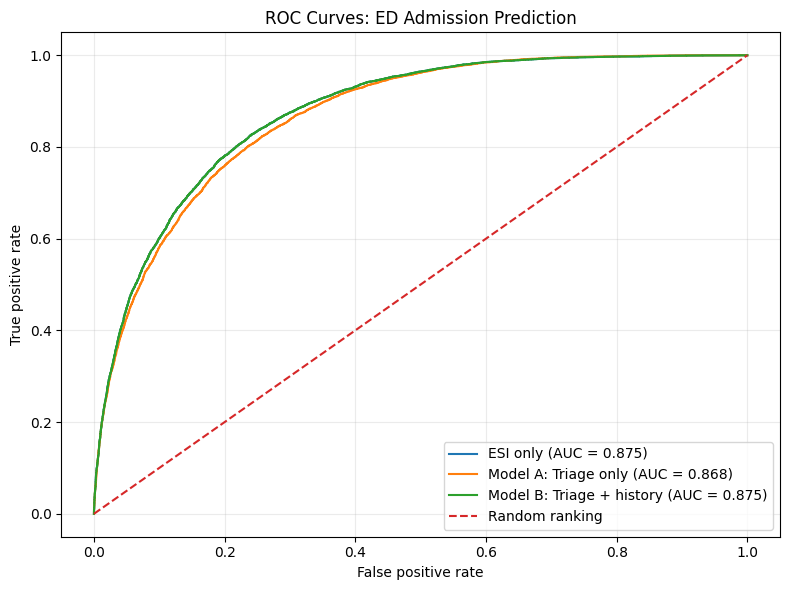

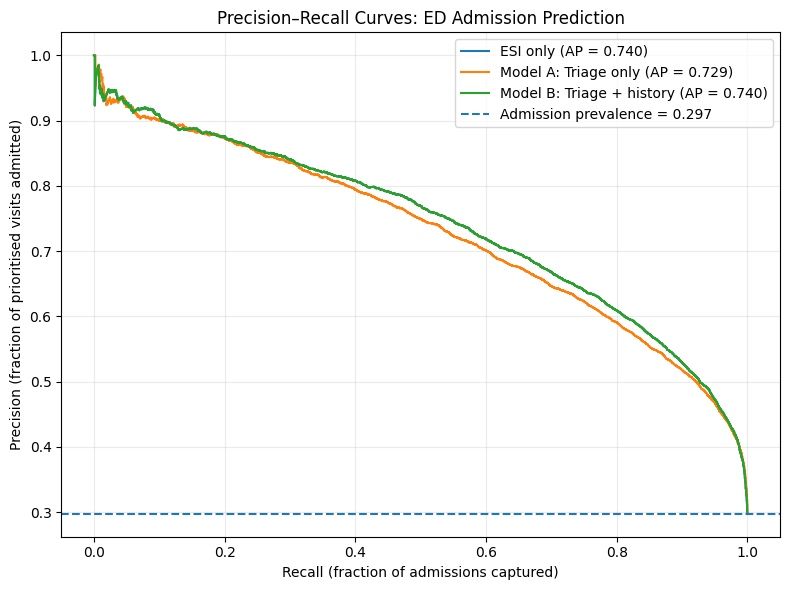

In [32]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# Use the existing numeric target directly
y_binary = np.asarray(y_test).astype(int).ravel()

assert set(np.unique(y_binary)) == {0, 1}
assert len(y_binary) == len(prob_a) == len(prob_b) == len(probs)

models = [
    ("ESI only", probs),
    ("Model A: Triage only", prob_a),
    ("Model B: Triage + history", prob_b)
]

# ROC curves
plt.figure(figsize=(8, 6))

for name, scores in models:
    fpr, tpr, _ = roc_curve(y_binary, scores)
    auc = roc_auc_score(y_binary, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves: ED Admission Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Precision–recall curves
plt.figure(figsize=(8, 6))

for name, scores in models:
    precision, recall, _ = precision_recall_curve(y_binary, scores)
    ap = average_precision_score(y_binary, scores)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y_binary.mean(),
    linestyle="--",
    label=f"Admission prevalence = {y_binary.mean():.3f}"
)
plt.xlabel("Recall (fraction of admissions captured)")
plt.ylabel("Precision (fraction of prioritised visits admitted)")
plt.title("Precision–Recall Curves: ED Admission Prediction")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [33]:

# Find where 'probs' was assigned in your executed notebook history
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    lines = cell.splitlines()
    matches = [
        line for line in lines
        if "probs =" in line or "probs=" in line
    ]
    if matches:
        print(f"\n--- Cell {i} ---")
        print("\n".join(lines[:30]))



--- Cell 33 ---

# Find where 'probs' was assigned in your executed notebook history
for i, cell in enumerate(get_ipython().history_manager.input_hist_raw):
    lines = cell.splitlines()
    matches = [
        line for line in lines
        if "probs =" in line or "probs=" in line
    ]
    if matches:
        print(f"\n--- Cell {i} ---")
        print("\n".join(lines[:30]))


In [35]:

import re

history = get_ipython().history_manager.input_hist_raw

# Find actual assignments to 'probs'
print("=== Assignments to probs ===")
found = False

for i, cell in enumerate(history):
    if re.search(r"^\s*probs\s*=", cell, flags=re.MULTILINE):
        print(f"\n--- Cell {i} ---")
        print(cell[:4000])
        found = True

if not found:
    print("No direct assignment to probs found.")

# Find the ESI baseline construction
print("\n=== Cells defining the ESI baseline ===")

for i, cell in enumerate(history):
    if "benchmark_results" in cell or "esi_test" in cell:
        print(f"\n--- Cell {i} ---")
        print(cell[:4000])


=== Assignments to probs ===
No direct assignment to probs found.

=== Cells defining the ESI baseline ===

--- Cell 10 ---

import numpy as np
import pandas as pd

# Recover the ESI values in exactly the same order as the test set
esi_test = pd.to_numeric(
    df.loc[y_test.index, "esi"], errors="coerce"
).to_numpy()

y_array = np.asarray(y_test, dtype=int)
prob_a_array = np.asarray(prob_a)
prob_b_array = np.asarray(prob_b)

assert len(esi_test) == len(y_array) == len(prob_a_array) == len(prob_b_array)

# Fixed random numbers make ties reproducible
rng = np.random.default_rng(42)
tie_breaker = rng.random(len(y_array))

# Lower ESI means higher acuity.
# Missing ESI values are placed after all recorded ESI levels.
esi_rank = np.where(np.isnan(esi_test), 999, esi_test)

# Sort: lowest ESI first, then random tie-breaker
esi_order = np.lexsort((tie_breaker, esi_rank))

def evaluate_ranking(y_true, ranking, method_name):
    n = len(y_true)
    total_admissions = int(np.sum(y_true))
    ro

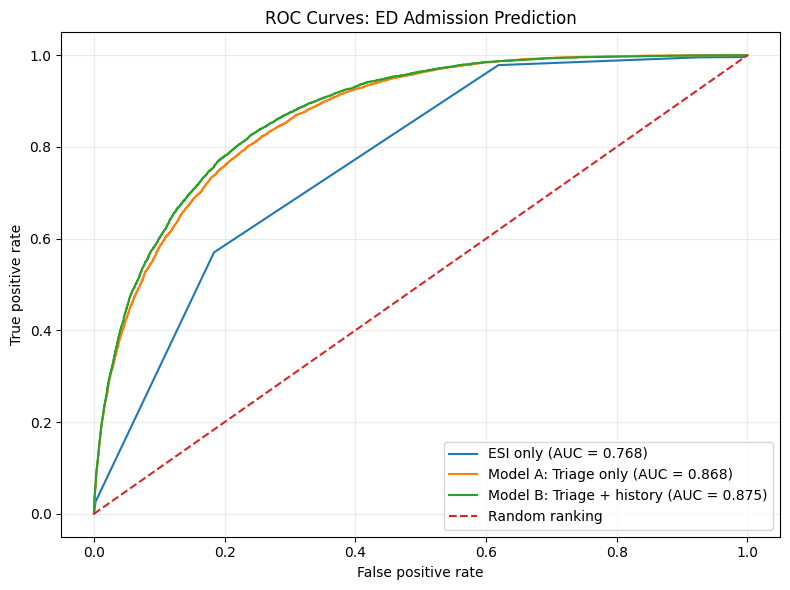

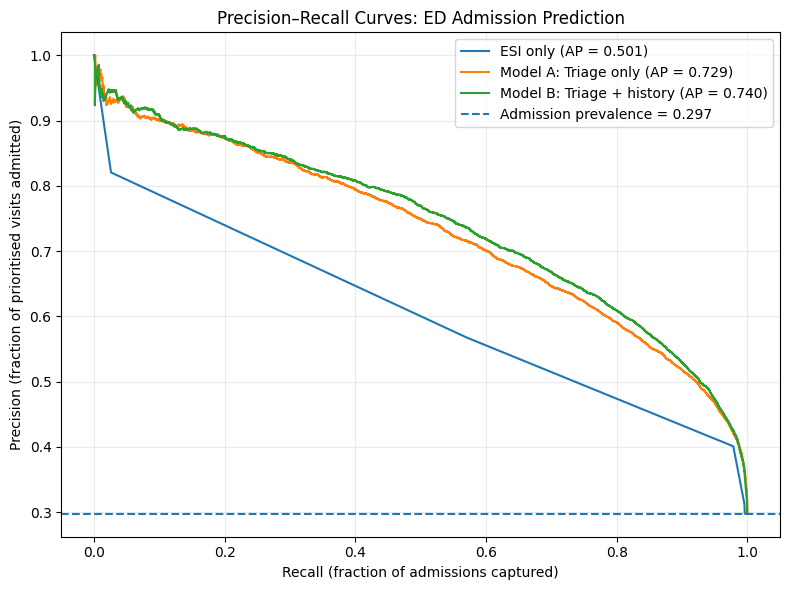


Metric summary
ESI only: ROC-AUC = 0.7678, Average precision = 0.5005
Model A: Triage only: ROC-AUC = 0.8685, Average precision = 0.7285
Model B: Triage + history: ROC-AUC = 0.8754, Average precision = 0.7399


In [36]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

y_binary = np.asarray(y_test, dtype=int).ravel()

# Lower ESI means higher acuity.
# Missing ESI is ranked after all recorded ESI levels.
esi_values = np.asarray(esi_test, dtype=float)
esi_rank = np.where(np.isnan(esi_values), 999, esi_values)
esi_score = -esi_rank

models = [
    ("ESI only", esi_score),
    ("Model A: Triage only", np.asarray(prob_a)),
    ("Model B: Triage + history", np.asarray(prob_b))
]

assert all(len(scores) == len(y_binary) for _, scores in models)
assert set(np.unique(y_binary)) == {0, 1}

# ROC curves
plt.figure(figsize=(8, 6))

for name, scores in models:
    fpr, tpr, _ = roc_curve(y_binary, scores)
    auc = roc_auc_score(y_binary, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves: ED Admission Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Precision–recall curves
plt.figure(figsize=(8, 6))

for name, scores in models:
    precision, recall, _ = precision_recall_curve(y_binary, scores)
    ap = average_precision_score(y_binary, scores)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y_binary.mean(),
    linestyle="--",
    label=f"Admission prevalence = {y_binary.mean():.3f}"
)
plt.xlabel("Recall (fraction of admissions captured)")
plt.ylabel("Precision (fraction of prioritised visits admitted)")
plt.title("Precision–Recall Curves: ED Admission Prediction")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Print exact metrics for reporting
print("\nMetric summary")
for name, scores in models:
    print(
        f"{name}: "
        f"ROC-AUC = {roc_auc_score(y_binary, scores):.4f}, "
        f"Average precision = {average_precision_score(y_binary, scores):.4f}"
    )


Calibration metrics (lower is better):


,Model,Brier score,Log loss
0,Model A: Triage only,0.1322,0.4040
1,Model B: Triage + history,0.1286,0.3959


Admission prevalence: 0.2973
Brier score for constant-prevalence prediction: 0.2089


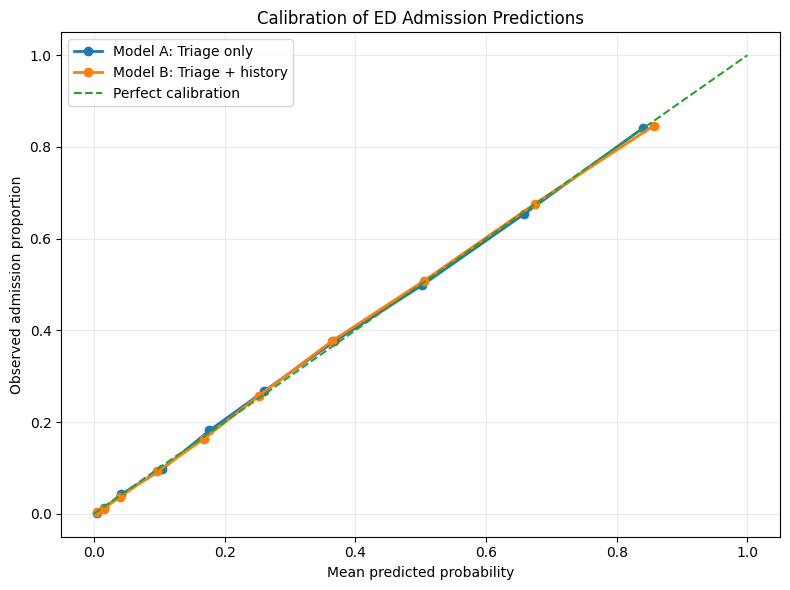

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

# Reuse the existing held-out test outcomes and predictions
y_binary = np.asarray(y_test, dtype=int).ravel()
p_a = np.asarray(prob_a, dtype=float).ravel()
p_b = np.asarray(prob_b, dtype=float).ravel()

assert len(y_binary) == len(p_a) == len(p_b)
assert set(np.unique(y_binary)) == {0, 1}
assert np.all(np.isfinite(p_a)) and np.all(np.isfinite(p_b))
assert np.all((p_a >= 0) & (p_a <= 1))
assert np.all((p_b >= 0) & (p_b <= 1))

predictions = {
    "Model A: Triage only": p_a,
    "Model B: Triage + history": p_b
}

# 1. Calculate probability-calibration metrics
results = []

for name, probabilities in predictions.items():
    results.append({
        "Model": name,
        "Brier score": brier_score_loss(y_binary, probabilities),
        "Log loss": log_loss(y_binary, probabilities)
    })

metrics_df = pd.DataFrame(results)
print("Calibration metrics (lower is better):")
display(metrics_df.round(4))

# Reference: predicting the same admission rate for every visit
prevalence = y_binary.mean()
print(f"Admission prevalence: {prevalence:.4f}")
print(
    "Brier score for constant-prevalence prediction:",
    round(brier_score_loss(
        y_binary, np.full(len(y_binary), prevalence)
    ), 4)
)

# 2. Plot reliability diagrams
plt.figure(figsize=(8, 6))

for name, probabilities in predictions.items():
    observed, predicted = calibration_curve(
        y_binary,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )
    plt.plot(
        predicted, observed,
        marker="o", linewidth=2, label=name
    )

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed admission proportion")
plt.title("Calibration of ED Admission Predictions")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [38]:

import re
import numpy as np
import pandas as pd

print("=" * 65)
print("1. DATASET AND TARGET")
print("=" * 65)

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Target column present:", "disposition" in df.columns)

    if "disposition" in df.columns:
        print("\nTarget distribution:")
        print(df["disposition"].value_counts(dropna=False))

    print("\nPotential patient/visit identifiers:")
    id_cols = [
        c for c in df.columns
        if any(term in c.lower() for term in [
            "patient_id", "patientid", "subject_id",
            "visit_id", "encounter_id", "mrn"
        ])
    ]
    print(id_cols if id_cols else "No obvious identifier columns found")

    print("\nHistorical feature columns:")
    print([
        c for c in df.columns
        if any(term in c.lower() for term in [
            "previous", "prior", "n_edvisits",
            "n_admissions", "history"
        ])
    ])
else:
    print("Variable df not found.")

print("\n" + "=" * 65)
print("2. EXISTING FEATURE LISTS")
print("=" * 65)

for name, obj in list(globals().items()):
    if (
        not name.startswith("_")
        and isinstance(obj, (list, tuple, pd.Index))
        and any(term in name.lower() for term in [
            "feature", "column", "numeric", "categorical",
            "cat_cols", "num_cols", "cc_cols"
        ])
    ):
        print(f"\n{name} ({len(obj)} items):")
        print(list(obj)[:100])

print("\n" + "=" * 65)
print("3. TRAIN/TEST SPLIT VARIABLES")
print("=" * 65)

for name in [
    "train_idx", "test_idx", "y_train", "y_test",
    "X_train", "X_test", "df_train", "df_test"
]:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name}: type={type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', None)}"
        )

print("\n" + "=" * 65)
print("4. SEARCH FOR SPLIT AND HISTORICAL-FEATURE CODE")
print("=" * 65)

history = get_ipython().history_manager.input_hist_raw

terms = [
    "train_test_split", "test_size", "random_state",
    "previousdispo", "n_edvisits", "n_admissions",
    "disposition", "drop(columns", "feature_cols"
]

for i, cell in enumerate(history):
    if any(term in cell.lower() for term in terms):
        print(f"\n--- Cell {i} ---")
        print(cell[:2200])


1. DATASET AND TARGET
Dataset shape: (150000, 218)
Target column present: True

Target distribution:
disposition
Discharge    105404
Admit         44596
Name: count, dtype: int64

Potential patient/visit identifiers:
No obvious identifier columns found

Historical feature columns:
['cc_seizure-priorhxof', 'n_edvisits', 'n_admissions', 'previousdispo']

2. EXISTING FEATURE LISTS

cc_cols (200 items):
['cc_abdominalcramping', 'cc_abdominaldistention', 'cc_abdominalpain', 'cc_abdominalpainpregnant', 'cc_abnormallab', 'cc_abscess', 'cc_addictionproblem', 'cc_agitation', 'cc_alcoholintoxication', 'cc_alcoholproblem', 'cc_allergicreaction', 'cc_alteredmentalstatus', 'cc_animalbite', 'cc_ankleinjury', 'cc_anklepain', 'cc_anxiety', 'cc_arminjury', 'cc_armpain', 'cc_armswelling', 'cc_assaultvictim', 'cc_asthma', 'cc_backpain', 'cc_bleeding/bruising', 'cc_blurredvision', 'cc_bodyfluidexposure', 'cc_breastpain', 'cc_breathingdifficulty', 'cc_breathingproblem', 'cc_burn', 'cc_cardiacarrest', 'cc_c

In [39]:

# Final structural checks: no model fitting or data modification

checks = {}

# 1. Train/test index integrity
checks["No train/test index overlap"] = (
    len(set(train_idx) & set(test_idx)) == 0
)
checks["Expected 80/20 split"] = (
    len(train_idx) == 120000 and len(test_idx) == 30000
)
checks["Unique indices in each split"] = (
    len(np.unique(train_idx)) == len(train_idx)
    and len(np.unique(test_idx)) == len(test_idx)
)

# 2. Target excluded from predictors
checks["Target excluded from Model A"] = (
    "disposition" not in model_a_cols
)
checks["Target excluded from Model B"] = (
    "disposition" not in model_b_cols
)

# 3. Model B adds only the intended history variables
checks["Model B contains all Model A features"] = (
    set(model_a_cols).issubset(set(model_b_cols))
)
checks["Added history features are as expected"] = (
    set(model_b_cols) - set(model_a_cols)
    == {"n_edvisits", "n_admissions", "previousdispo"}
)

# 4. Verify both fitted pipelines have the expected classes
checks["Model A fitted"] = hasattr(model_a, "classes_")
checks["Model B fitted"] = hasattr(model_b, "classes_")

print("AUDIT RESULTS")
for check, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} — {check}")

print("\nModel A classes:", model_a.classes_)
print("Model B classes:", model_b.classes_)

print("\nModel A training rows:", len(X_train))
print("Model B feature count:", len(model_b_cols))
print("Test rows:", len(y_test))
print("Patient identifier available:", False)


AUDIT RESULTS
PASS — No train/test index overlap
PASS — Expected 80/20 split
PASS — Unique indices in each split
PASS — Target excluded from Model A
PASS — Target excluded from Model B
PASS — Model B contains all Model A features
PASS — Added history features are as expected
PASS — Model A fitted
PASS — Model B fitted

Model A classes: [0 1]
Model B classes: [0 1]


NameError: name 'X_train' is not defined

In [40]:

print("Model A training rows:", len(train_idx))
print("Model B feature count:", len(model_b_cols))
print("Test rows:", len(test_idx))


Model A training rows: 120000
Model B feature count: 217
Test rows: 30000
